In [1]:
from pathlib import Path
from PIL import Image

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches

In [2]:
DATA_PATH = Path("../data/raw")

train_path = DATA_PATH / "train"
val_path = DATA_PATH / "Val"

print("Train:", train_path.exists())
print("Val:", val_path.exists())

Train: True
Val: True


In [3]:
class_names = sorted([
    folder.name
    for folder in train_path.iterdir()
    if folder.is_dir()
])

print(class_names)
print("Classes:", len(class_names))

['Glioma', 'Meningioma', 'No Tumor', 'Pituitary']
Classes: 4


In [4]:
data_counts = []

for split in ["train", "Val"]:
    for class_name in class_names:

        folder = DATA_PATH / split / class_name

        images = list((folder / "images").glob("*.jpg"))
        labels = list((folder / "labels").glob("*.txt"))

        data_counts.append({
            "split": split,
            "class": class_name,
            "images": len(images),
            "labels": len(labels)
        })

counts_df = pd.DataFrame(data_counts)

counts_df

,split,class,images,labels
0,train,Glioma,1153,1153
1,train,Meningioma,1449,1449
2,train,No Tumor,711,711
3,train,Pituitary,1424,1424
4,Val,Glioma,136,136
5,Val,Meningioma,140,140
6,Val,No Tumor,100,100
7,Val,Pituitary,136,136


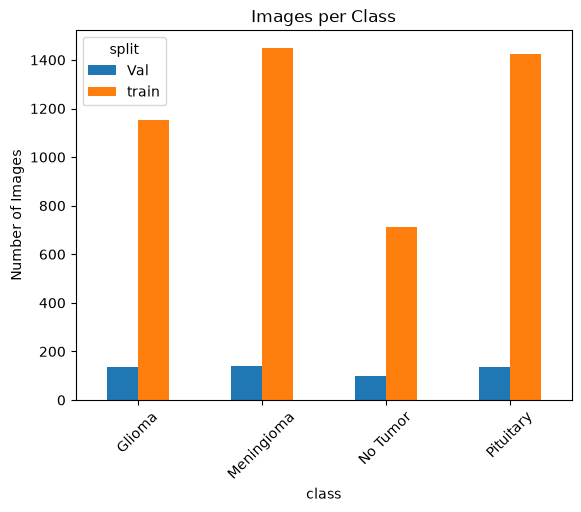

In [5]:
counts_df.pivot(
    index="class",
    columns="split",
    values="images"
).plot(kind="bar")

plt.title("Images per Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)
plt.show()

In [6]:
image_data = []
broken_images = []

for split in ["train", "Val"]:
    for class_name in class_names:

        folder = DATA_PATH / split / class_name / "images"

        for image_path in folder.iterdir():
            try:
                with Image.open(image_path) as image:
                    image_data.append({
                        "split": split,
                        "class": class_name,
                        "width": image.width,
                        "height": image.height,
                        "format": image.format,
                        "mode": image.mode
                    })

            except Exception:
                broken_images.append(str(image_path))

images_df = pd.DataFrame(image_data)

print("Total images:", len(images_df))
print("Broken images:", len(broken_images))

Total images: 5249
Broken images: 0


In [7]:
print(images_df[["width", "height"]].describe())

print(images_df["format"].value_counts())

print(images_df["mode"].value_counts())

             width       height
count  5249.000000  5249.000000
mean    481.947609   484.467518
std     106.057852   100.134268
min     150.000000   168.000000
25%     512.000000   512.000000
50%     512.000000   512.000000
75%     512.000000   512.000000
max    1375.000000  1446.000000
format
JPEG    5245
PNG        4
Name: count, dtype: int64
mode
RGB     4247
L        998
RGBA       3
P          1
Name: count, dtype: int64


In [8]:
missing_labels = []
extra_labels = []

for split in ["train", "Val"]:
    for class_name in class_names:

        folder = DATA_PATH / split / class_name

        image_names = {
            file.stem
            for file in (folder / "images").iterdir()
            if file.suffix.lower() in [".jpg", ".jpeg", ".png"]
        }

        label_names = {
            file.stem
            for file in (folder / "labels").glob("*.txt")
        }

        for name in image_names - label_names:
            missing_labels.append((split, class_name, name))

        for name in label_names - image_names:
            extra_labels.append((split, class_name, name))

print("Missing labels:", len(missing_labels))
print("Extra labels:", len(extra_labels))

Missing labels: 2
Extra labels: 2


In [9]:
label_folder = train_path / "Glioma" / "labels"

label_path = sorted(label_folder.glob("*.txt"))[0]

print("File:", label_path.name)

with open(label_path) as file:
    print(file.read())

File: Te-glTr_0000.txt
0 0.555664 0.653320 0.146484 0.193359



In [12]:
invalid_labels = []

for split in ["train", "Val"]:
    for class_name in class_names:

        folder = DATA_PATH / split / class_name / "labels"

        for label_path in folder.glob("*.txt"):

            with open(label_path) as file:
                lines = file.readlines()

            for line in lines:
                try:
                    values = list(map(float, line.split()))

                    if len(values) != 5:
                        raise ValueError()

                    cls, x, y, w, h = values

                    if cls < 0 or not cls.is_integer():
                        raise ValueError()

                    if not (0 <= x <= 1 and 0 <= y <= 1):
                        raise ValueError()

                    if w <= 0 or h <= 0:
                        raise ValueError()

                    if x - w/2 < 0 or x + w/2 > 1:
                        raise ValueError()

                    if y - h/2 < 0 or y + h/2 > 1:
                        raise ValueError()

                except ValueError:
                    invalid_labels.append(str(label_path))

print("Invalid annotations:", len(invalid_labels))

Invalid annotations: 15


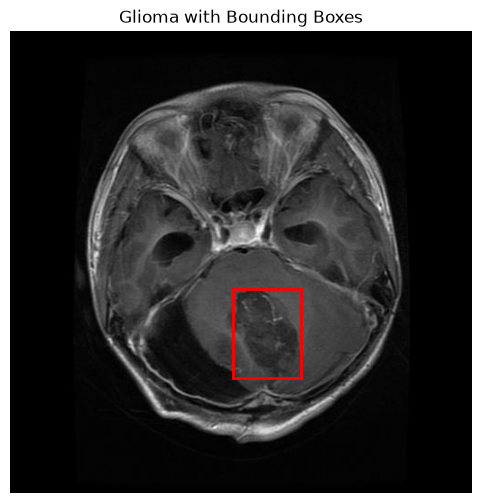

In [13]:
folder = train_path / "Glioma"

image_path = sorted((folder / "images").glob("*.jpg"))[0]
label_path = folder / "labels" / (image_path.stem + ".txt")

image = Image.open(image_path)
width, height = image.size

fig, ax = plt.subplots(figsize=(6, 6))

ax.imshow(image)

with open(label_path) as file:
    for line in file:

        cls, x, y, w, h = map(float, line.split())

        box_width = w * width
        box_height = h * height

        x_min = x * width - box_width / 2
        y_min = y * height - box_height / 2

        box = patches.Rectangle(
            (x_min, y_min),
            box_width,
            box_height,
            fill=False,
            edgecolor="red",
            linewidth=2
        )

        ax.add_patch(box)

ax.set_title("Glioma with Bounding Boxes")
ax.axis("off")

plt.show()

In [14]:
folder = train_path / "No Tumor" / "labels"

empty_labels = 0
total_labels = 0

for label_path in folder.glob("*.txt"):

    total_labels += 1

    if label_path.stat().st_size == 0:
        empty_labels += 1

print("Total labels:", total_labels)
print("Empty labels:", empty_labels)

Total labels: 711
Empty labels: 0


In [18]:
print("Missing labels:")
for item in missing_labels:
    print(item)

print("\nExtra labels:")
for item in extra_labels:
    print(item)

Missing labels:
('Val', 'No Tumor', 'image(55)')
('Val', 'No Tumor', 'image(61)')

Extra labels:
('Val', 'No Tumor', 'image(53)')
('Val', 'No Tumor', 'image(60)')


In [19]:
print("Invalid files:")

for path in sorted(set(invalid_labels)):
    print(path)

print("Total invalid files:", len(set(invalid_labels)))

Invalid files:
../data/raw/Val/No Tumor/labels/Tr-no_0058.txt
../data/raw/Val/No Tumor/labels/image(162).txt
../data/raw/Val/No Tumor/labels/image(319).txt
../data/raw/train/No Tumor/labels/3.txt
../data/raw/train/No Tumor/labels/Tr-noTr_0000.txt
../data/raw/train/No Tumor/labels/Tr-no_0810.txt
../data/raw/train/No Tumor/labels/Tr-no_0988.txt
../data/raw/train/No Tumor/labels/Tr-no_1083.txt
../data/raw/train/No Tumor/labels/image (11).txt
../data/raw/train/No Tumor/labels/image (58).txt
../data/raw/train/No Tumor/labels/image(110).txt
../data/raw/train/No Tumor/labels/image(116).txt
../data/raw/train/No Tumor/labels/image(231).txt
../data/raw/train/No Tumor/labels/image(317).txt
../data/raw/train/No Tumor/labels/image(318).txt
Total invalid files: 15


In [20]:
if invalid_labels:
    path = invalid_labels[0]

    print("File:", path)
    print(Path(path).read_text())

File: ../data/raw/train/No Tumor/labels/3.txt
2 0.512397 0.513051 0.770248 0.973899



In [21]:
from collections import Counter

for class_name in class_names:

    box_counts = []

    for label_path in (train_path / class_name / "labels").glob("*.txt"):

        with open(label_path) as file:
            lines = [line for line in file if line.strip()]

        box_counts.append(len(lines))

    print("\n", class_name)
    print(Counter(box_counts))


 Glioma
Counter({1: 860, 2: 246, 3: 38, 4: 9})

 Meningioma
Counter({1: 1326, 2: 116, 3: 5, 5: 2})

 No Tumor
Counter({1: 711})

 Pituitary
Counter({1: 1329, 2: 93, 3: 2})


In [22]:
folder = train_path / "No Tumor" / "labels"

label_files = sorted(folder.glob("*.txt"))

for label_path in label_files[:5]:

    print("\n", label_path.name)

    with open(label_path) as file:
        print(file.read())


 1.txt
2 0.502857 0.675714 0.851429 0.648571


 3.txt
2 0.512397 0.513051 0.770248 0.973899


 4.txt
2 0.525801 0.507601 0.809609 0.984797


 5.txt
2 0.497738 0.451357 0.737557 0.703620


 6.txt
2 0.499206 0.515079 0.671429 0.893651



In [23]:
for class_name in class_names:

    class_ids = set()

    folder = train_path / class_name / "labels"

    for label_path in folder.glob("*.txt"):

        with open(label_path) as file:

            for line in file:

                values = line.split()

                if values:
                    class_ids.add(values[0])

    print(class_name, ":", class_ids)

Glioma : {'0', '1', '3'}
Meningioma : {'0', '1', '3'}
No Tumor : {'2'}
Pituitary : {'1', '3'}


In [24]:
folder = val_path / "No Tumor"

for file in sorted(folder.rglob("*")):
    if "image(5" in file.name or "image(6" in file.name:
        print(file.relative_to(folder))

images/image(5).jpg
images/image(55).jpg
images/image(61).jpg
images/image(65).jpg
images/image(68).jpg
labels/image(5).txt
labels/image(53).txt
labels/image(60).txt
labels/image(65).txt
labels/image(68).txt


In [25]:
invalid_labels = []

for split in ["train", "Val"]:
    for class_name in class_names:

        folder = DATA_PATH / split / class_name / "labels"

        for label_path in folder.glob("*.txt"):

            with open(label_path) as file:
                for line in file:

                    try:
                        values = list(map(float, line.split()))

                        if len(values) != 5:
                            raise ValueError()

                        cls, x, y, w, h = values

                        if cls < 0 or not cls.is_integer():
                            raise ValueError()

                        if w <= 0 or h <= 0:
                            raise ValueError()

                        if x - w/2 < -0.001 or x + w/2 > 1.001:
                            raise ValueError()

                        if y - h/2 < -0.001 or y + h/2 > 1.001:
                            raise ValueError()

                    except ValueError:
                        invalid_labels.append(str(label_path))

print("Invalid annotations:", len(invalid_labels))

Invalid annotations: 0


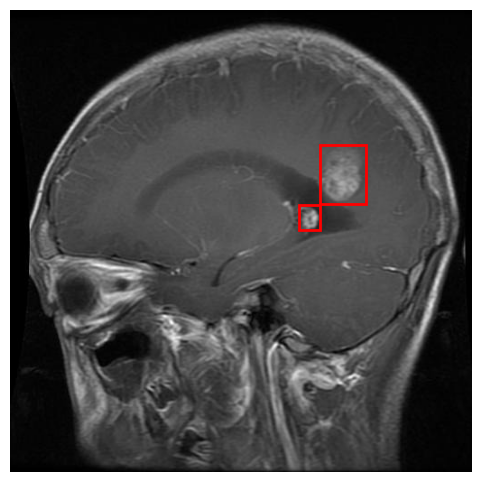

In [27]:
folder = train_path / "Glioma"

for label_path in (folder / "labels").glob("*.txt"):

    with open(label_path) as file:
        lines = file.readlines()

    if len(lines) > 1:
        break

image_path = folder / "images" / (label_path.stem + ".jpg")

image = Image.open(image_path)
width, height = image.size

fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(image)

for line in lines:

    cls, x, y, w, h = map(float, line.split())

    box_width = w * width
    box_height = h * height

    x_min = x * width - box_width / 2
    y_min = y * height - box_height / 2

    box = patches.Rectangle(
        (x_min, y_min),
        box_width,
        box_height,
        fill=False,
        edgecolor="red",
        linewidth=2
    )

    ax.add_patch(box)

ax.axis("off")
plt.show()